In [0]:
# Import analysis and clustering libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram


In [1]:
# Load wholesale customer data
df = pd.read_csv("Wholesale customers data.csv")

print("Wholesale customers dataset loaded successfully.")
print(f"Dataset size: {df.shape[0]} customers and {df.shape[1]} columns.")
print("First five customer records:")
display(df.head())
print("Dataset columns:", df.columns.tolist())


Wholesale customers dataset loaded successfully.
Dataset size: 440 customers and 8 columns.
First five customer records:
Dataset columns: ['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [2]:
# Summarize dataset structure and statistics
print("Dataset structure and data types:")
df.info()
print("\nSummary statistics for numeric columns:")
display(df.describe().T)


Dataset structure and data types:
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Summary statistics for numeric columns:


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


In [3]:
# Check missing values, duplicates, and category counts
print("Missing values by column:")
display(df.isna().sum().to_frame("Missing values"))
print(f"Duplicate rows: {df.duplicated().sum()}")
print("\nCustomer counts by Channel and Region:")
display(df[["Channel", "Region"]].value_counts().rename("Customer count").reset_index())


Missing values by column:
Duplicate rows: 0

Customer counts by Channel and Region:


,Missing values
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


,Channel,Region,Customer count
0,1,3,211
1,2,3,105
2,1,1,59
3,1,2,28
4,2,2,19
5,2,1,18


In [4]:
# Summarize spending correlations and averages
eda_features = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
print("Correlation between spending categories:")
display(df[eda_features].corr().round(2))
print("Average spending by category:")
display(df[eda_features].mean().sort_values(ascending=False).to_frame("Average spending"))


Correlation between spending categories:
Average spending by category:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.00,0.10,-0.01,0.35,-0.10,0.24
Milk,0.10,1.00,0.73,0.12,0.66,0.41
Grocery,-0.01,0.73,1.00,-0.04,0.92,0.21
Frozen,0.35,0.12,-0.04,1.00,-0.13,0.39
Detergents_Paper,-0.10,0.66,0.92,-0.13,1.00,0.07
Delicassen,0.24,0.41,0.21,0.39,0.07,1.00


,Average spending
Fresh,12000.297727
Grocery,7951.277273
Milk,5796.265909
Frozen,3071.931818
Detergents_Paper,2881.493182
Delicassen,1524.870455


Histograms show the distribution of spending across product categories.


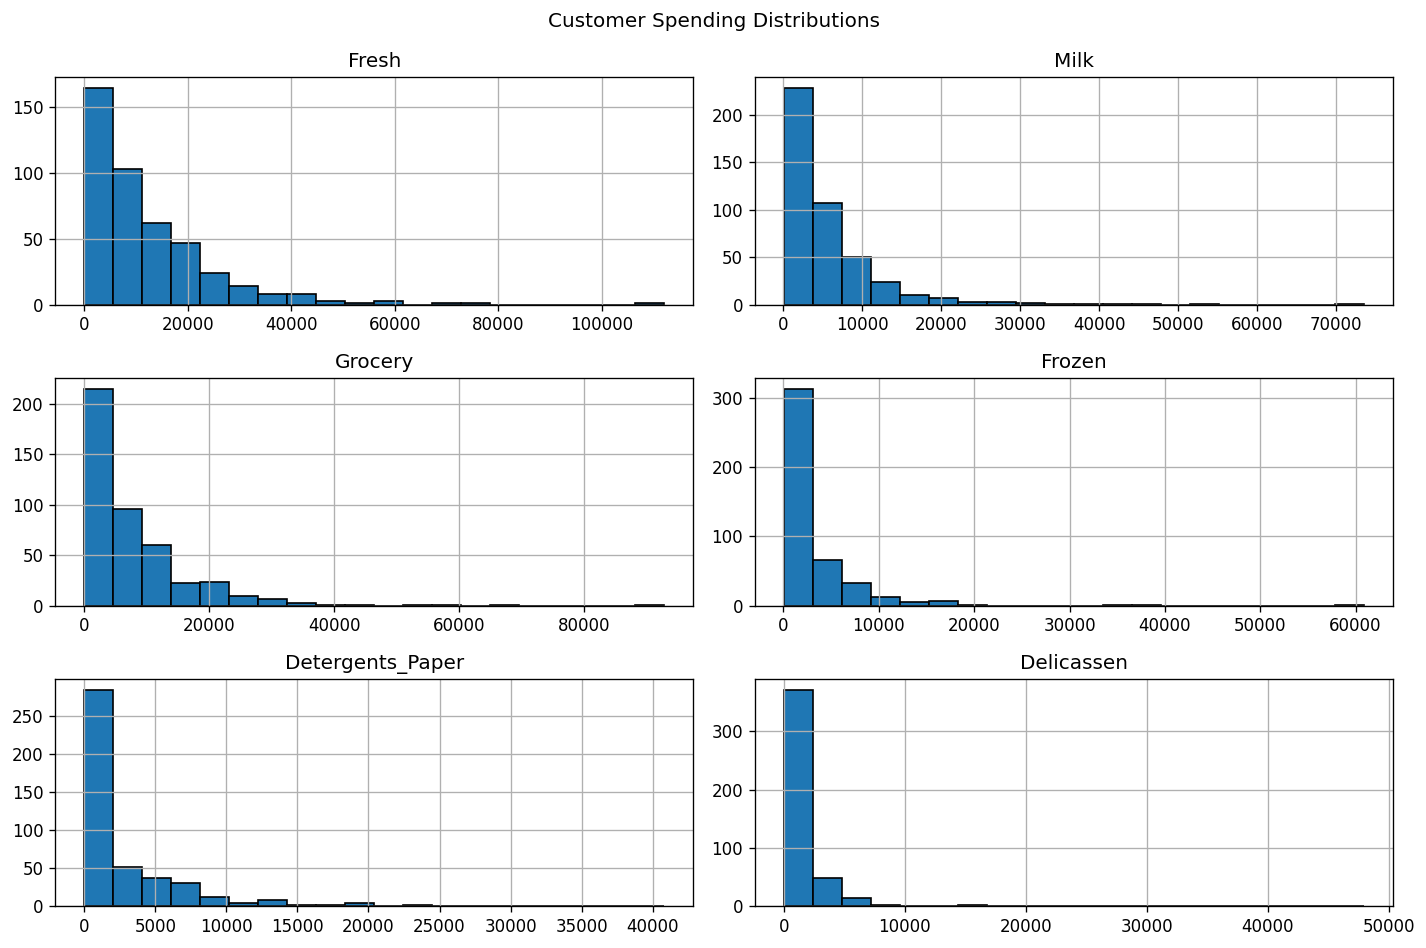

In [5]:
# Explore spending distributions with histograms
features = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
print("Histograms show the distribution of spending across product categories.")
df[features].hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Customer Spending Distributions")
plt.tight_layout()
plt.show()


Scatter plot comparing Fresh and Grocery spending per customer.


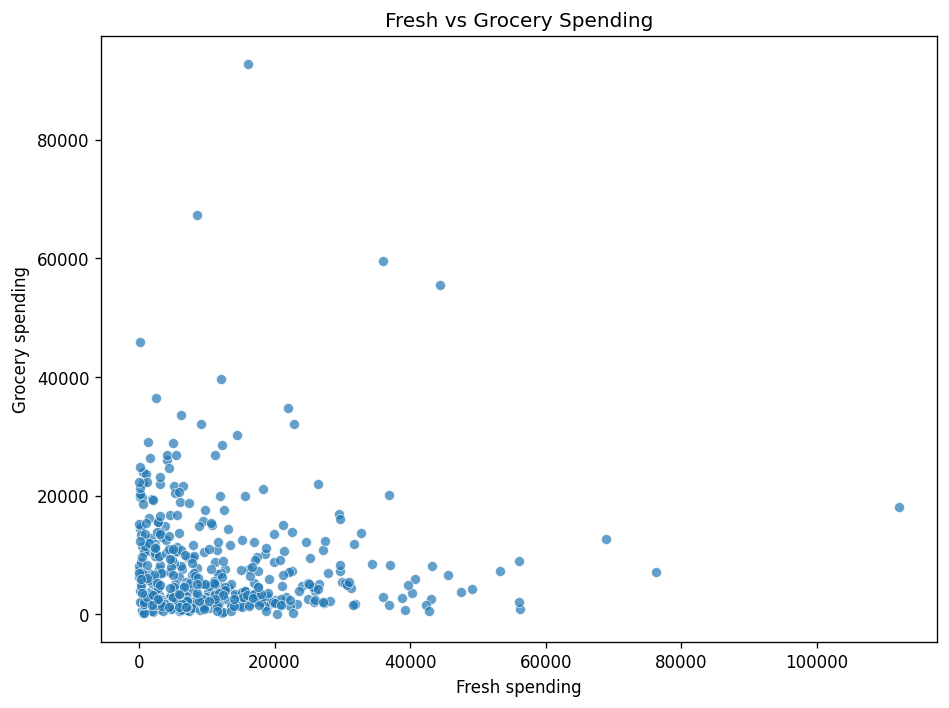

In [6]:
# Plot Fresh and Grocery spending
print("Scatter plot comparing Fresh and Grocery spending per customer.")
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Fresh", y="Grocery", alpha=0.7)
plt.title("Fresh vs Grocery Spending")
plt.xlabel("Fresh spending")
plt.ylabel("Grocery spending")
plt.tight_layout()
plt.show()


Box plots show the spread and outliers in customer spending by category.


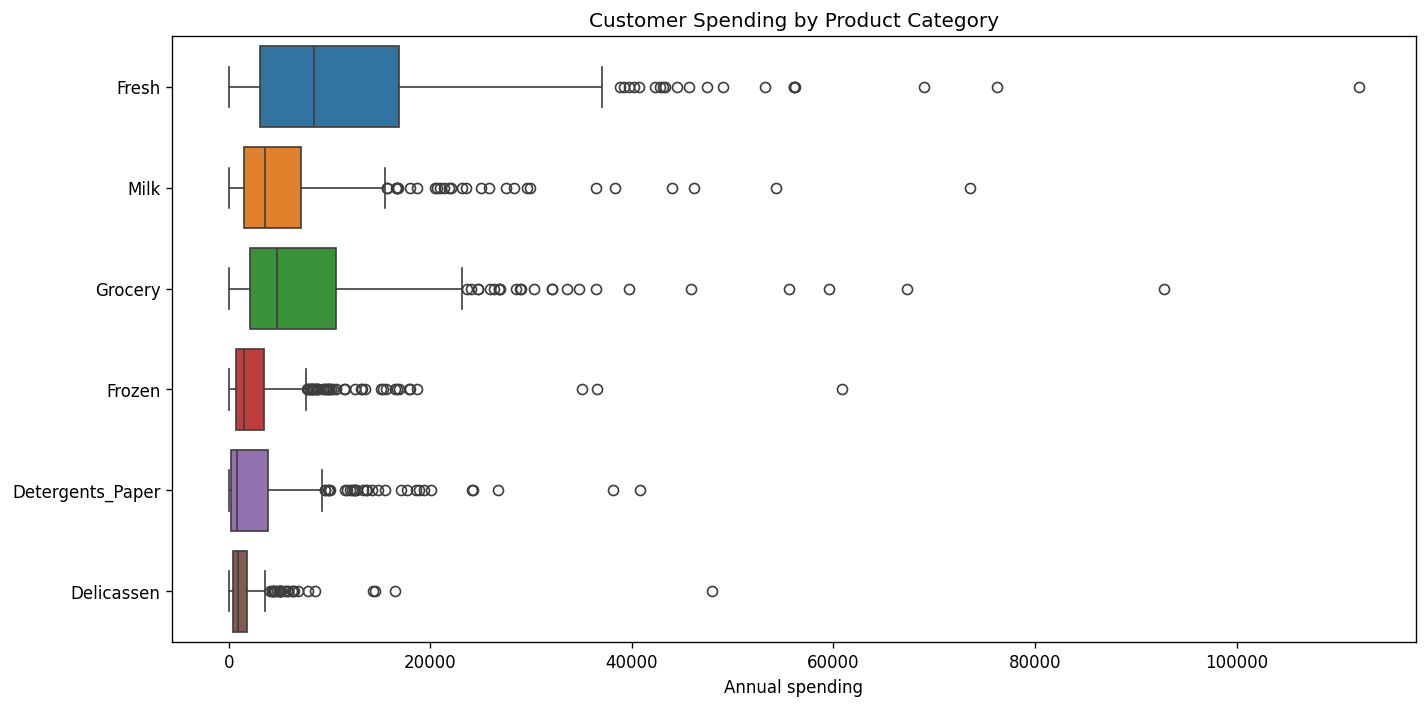

In [7]:
# Compare spending with box plots
print("Box plots show the spread and outliers in customer spending by category.")
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[features], orient="h")
plt.title("Customer Spending by Product Category")
plt.xlabel("Annual spending")
plt.tight_layout()
plt.show()


Heatmap of correlations between product category spending.


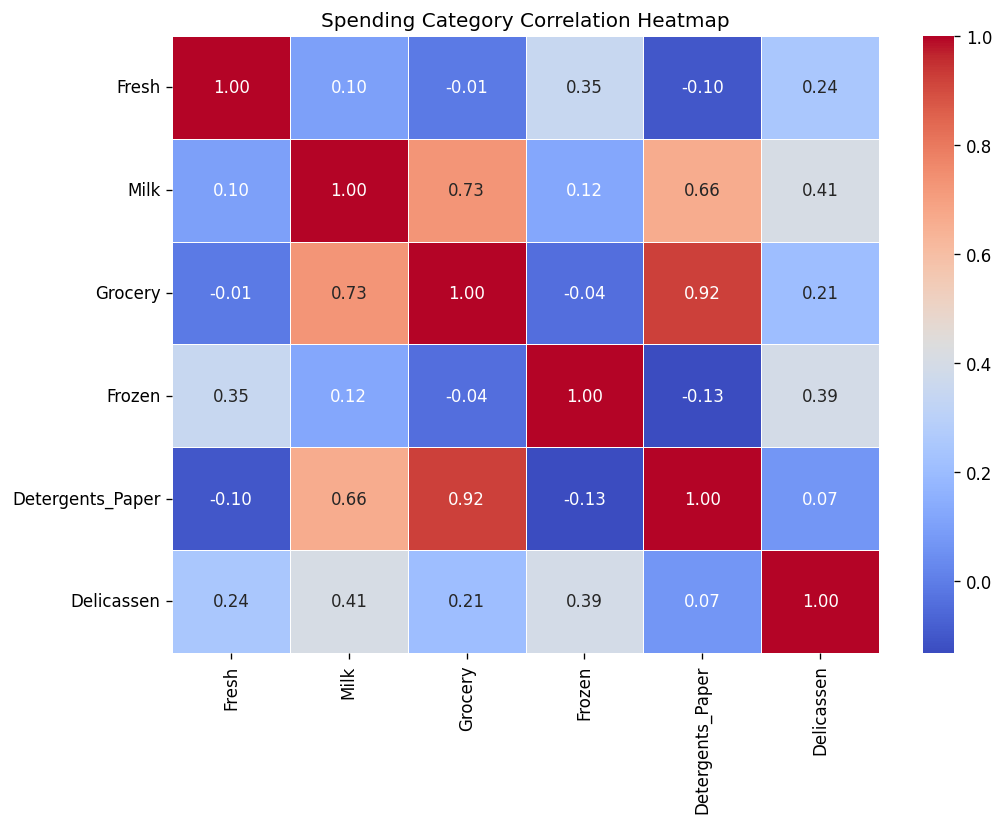

In [8]:
# Plot spending correlation heatmap
print("Heatmap of correlations between product category spending.")
spending_correlation = df[features].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(spending_correlation, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Spending Category Correlation Heatmap")
plt.tight_layout()
plt.show()


Bar plot of average annual spending by product category.


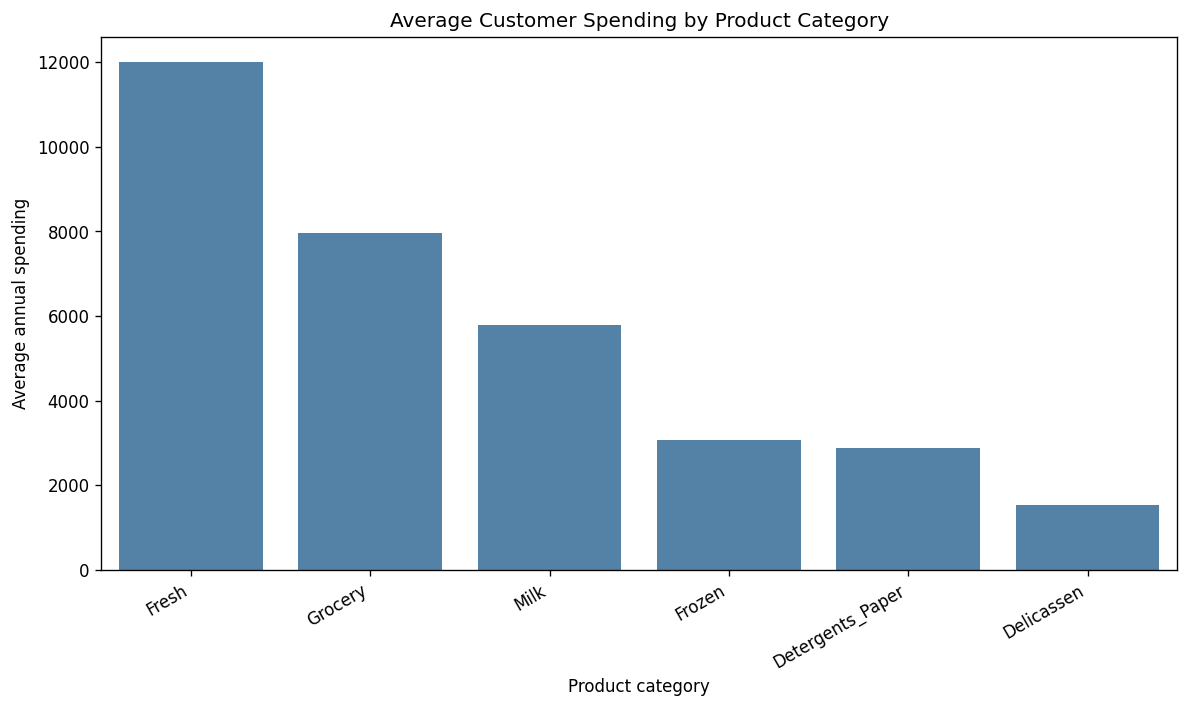

In [9]:
# Plot average spending by category
print("Bar plot of average annual spending by product category.")
average_spending = df[features].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=average_spending.index, y=average_spending.values, color="steelblue")
plt.title("Average Customer Spending by Product Category")
plt.xlabel("Product category")
plt.ylabel("Average annual spending")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [10]:
# Select features, handle missing values, and scale data
features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

missing_columns = [column for column in features if column not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns in dataset: {missing_columns}")

X = df[features].copy()
X = X.fillna(X.median(numeric_only=True))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=X.index)

print("Selected six spending features, filled missing values with column medians, and standardized the data.")
print("First five standardized customer records:")
display(X_scaled_df.head())
print("Standardized feature means (approximately zero):")
print(X_scaled_df.mean().round(4))


Selected six spending features, filled missing values with column medians, and standardized the data.
First five standardized customer records:
Standardized feature means (approximately zero):
Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


Elbow plot of within-cluster sum of squares for K = 1 to 10.


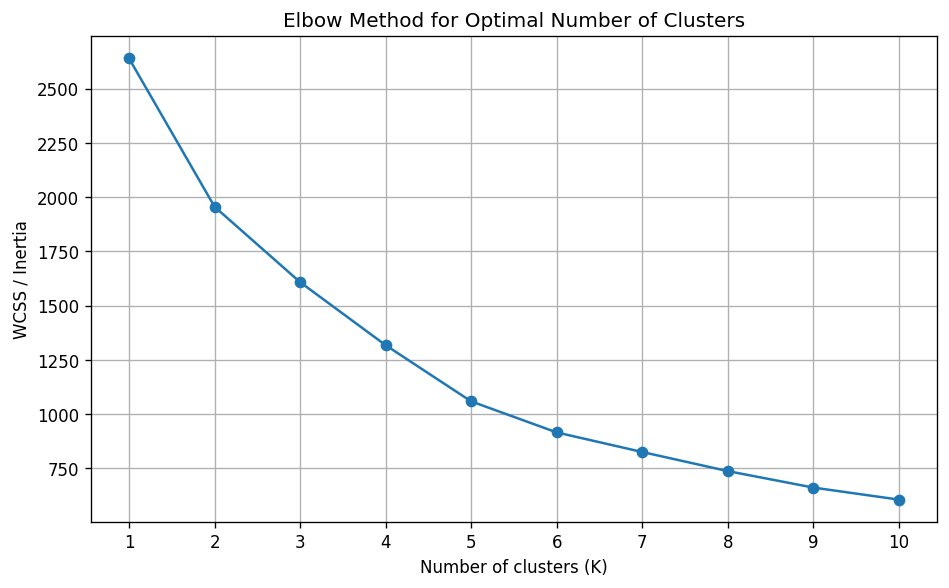

In [11]:
# Find candidate cluster counts with the elbow method
wcss = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

print("Elbow plot of within-cluster sum of squares for K = 1 to 10.")
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), wcss, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()


In [12]:
# Evaluate cluster counts with silhouette scores
silhouette_values = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_values.append(score)

silhouette_table = pd.DataFrame({
    "Number of Clusters (K)": range(2, 11),
    "Silhouette Score": silhouette_values
})

print("Silhouette scores for K = 2 to 10:")
display(silhouette_table.round(4))

suggested_k = int(
    silhouette_table.loc[
        silhouette_table["Silhouette Score"].idxmax(),
        "Number of Clusters (K)"
    ]
)
print(f"Highest silhouette score suggests {suggested_k} clusters.")


Silhouette scores for K = 2 to 10:
Highest silhouette score suggests 3 clusters.


,Number of Clusters (K),Silhouette Score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [13]:
# Fit K-Means and summarize cluster assignments
K = suggested_k
kmeans_model = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

df_kmeans = df.copy()
df_kmeans["Kmeans_Clusters"] = kmeans_labels

print(f"K-Means clustering completed with {K} clusters.")
print("Customer count in each cluster:")
print(df_kmeans["Kmeans_Clusters"].value_counts().sort_index())
print("First five customers with assigned cluster labels:")
display(df_kmeans.head())


K-Means clustering completed with 3 clusters.
Customer count in each cluster:
Kmeans_Clusters
0     45
1    393
2      2
Name: count, dtype: int64
First five customers with assigned cluster labels:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Kmeans_Clusters
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


Full hierarchical clustering dendrogram.


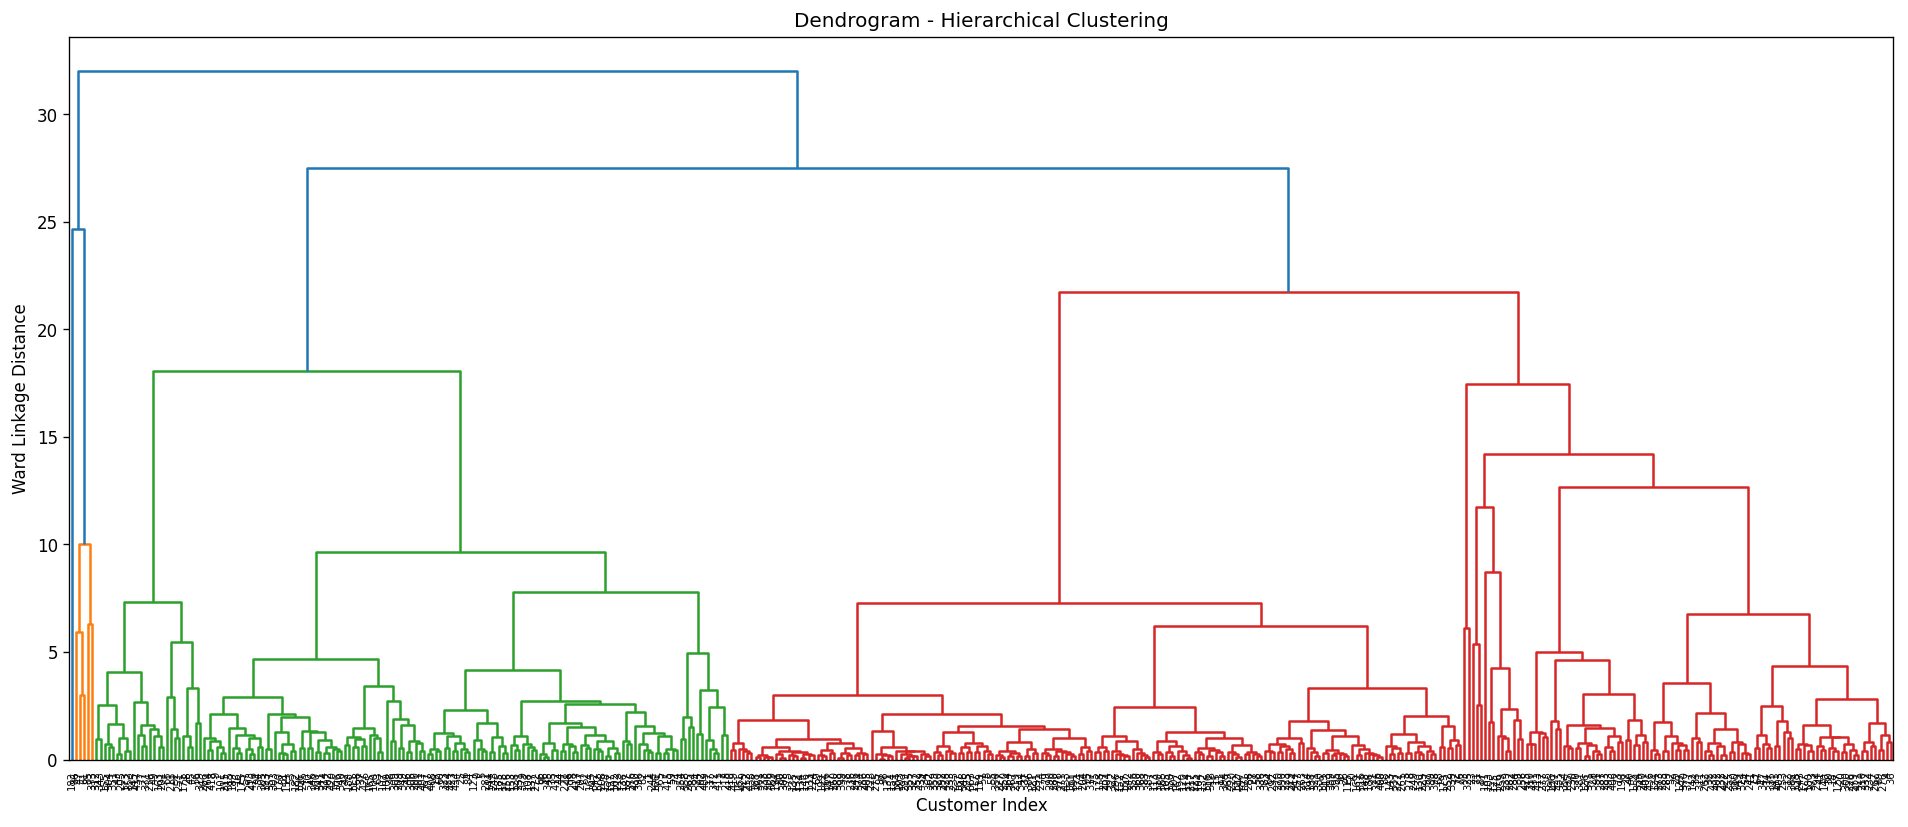

In [14]:
# Build a hierarchical clustering dendrogram
z = linkage(X_scaled, method="ward", metric="euclidean")

print("Full hierarchical clustering dendrogram.")
plt.figure(figsize=(16, 7))
dendrogram(z, leaf_rotation=90, leaf_font_size=6)
plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Customer Index")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()


Truncated dendrogram showing the last 30 merged groups.


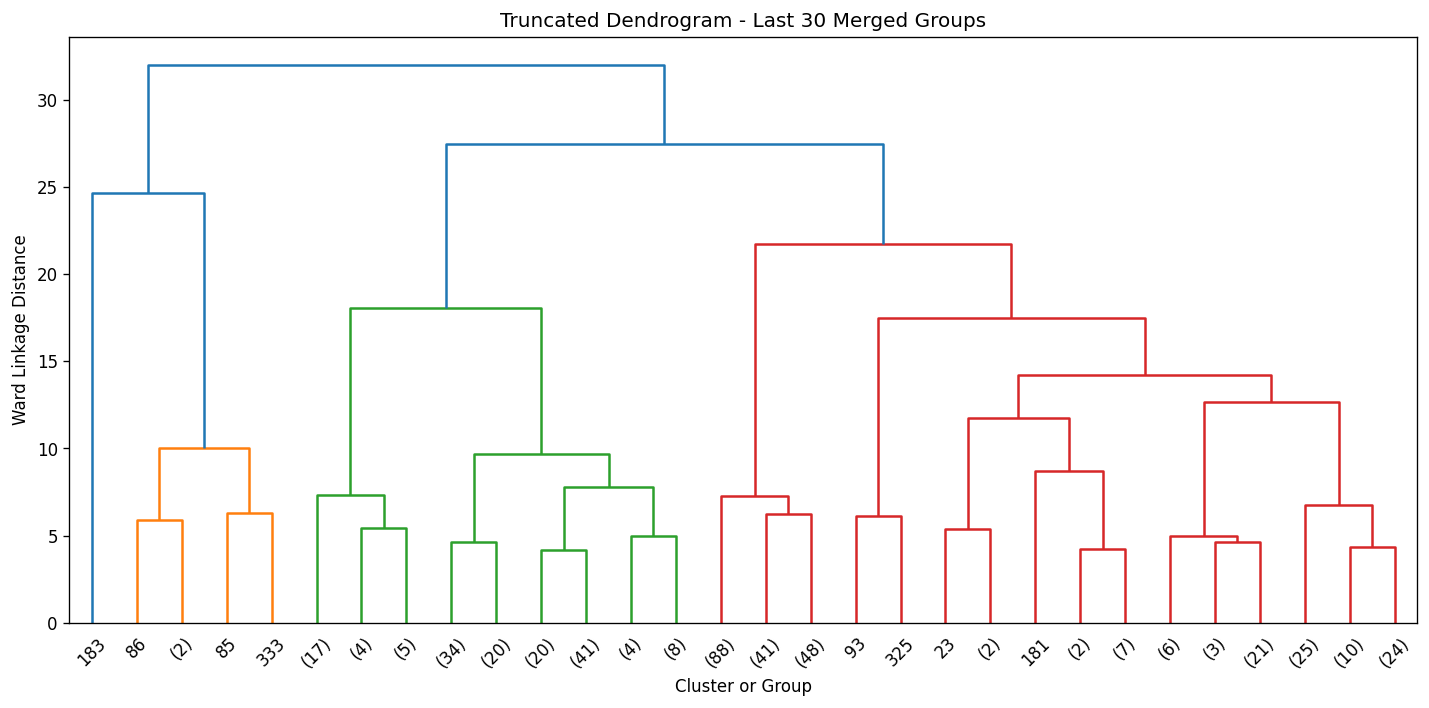

In [15]:
# Display a readable truncated dendrogram
print("Truncated dendrogram showing the last 30 merged groups.")
plt.figure(figsize=(12, 6))
dendrogram(
    z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=45
)
plt.title("Truncated Dendrogram - Last 30 Merged Groups")
plt.xlabel("Cluster or Group")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()


The two PCA components explain 72.46% of the data variance.
Scatter plot of customers grouped by their K-Means cluster.


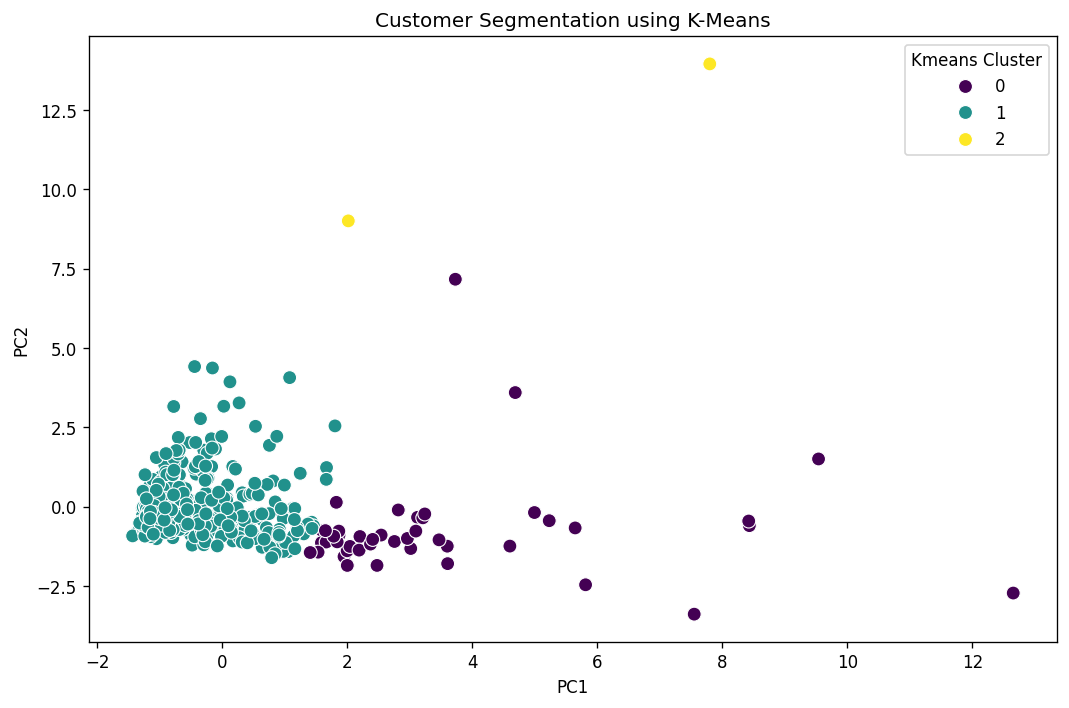

In [16]:
# Plot clusters in two PCA dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_.sum() * 100
print(f"The two PCA components explain {explained_variance:.2f}% of the data variance.")
print("Scatter plot of customers grouped by their K-Means cluster.")

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Kmeans Cluster": kmeans_labels
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="Kmeans Cluster",
    palette="viridis",
    s=70
)
plt.title("Customer Segmentation using K-Means")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()
